# IADS5 · TP integrador — Ortelana Textil
### Actividad 12 · Clustering: k-means y jerárquico

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 12 · Clustering: k-means y jerárquico

**Qué se espera:** Sin usar el target, escalá features numéricas y evaluá k-means para k=2..10 mediante inercia y silueta. Interpretá centroides/perfiles; aplicá clustering jerárquico con Ward y dendrograma truncado; visualizá segmentos en 2D o PCA.

**Evidencia a entregar:** Codo, silueta, perfiles, dendrograma y visualización interpretada.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


,inercia,silueta
k,,
2,1929.0057,0.5676
3,1131.1803,0.5035
4,738.3212,0.4842
5,527.7486,0.4640
6,410.8527,0.4448
7,327.7613,0.4470
8,277.8240,0.4252
9,248.5636,0.4145
10,220.7591,0.4030


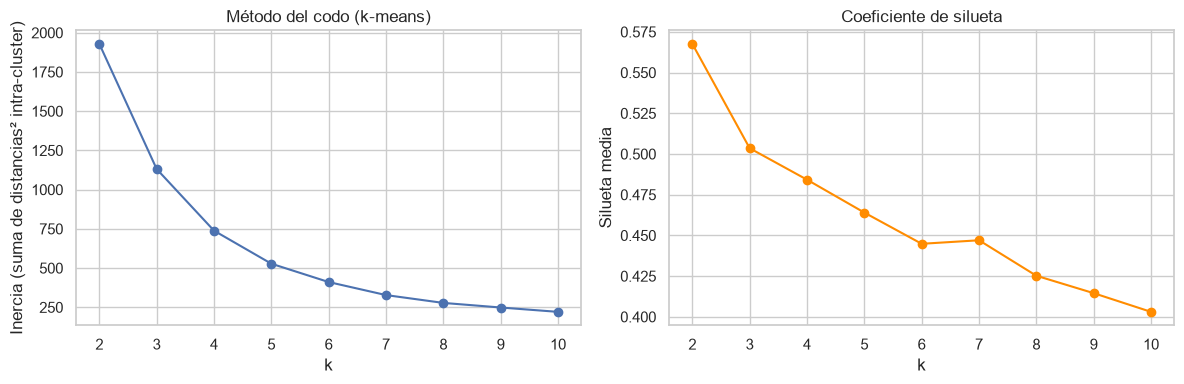

In [2]:
# 12.1 Features de clustering (SIN el target): Metros1 y Metros2 en escala log, luego estandarizadas
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

X_clu_original = train[["Metros1", "Metros2"]]          # solo filas de train
escalador = StandardScaler()
X_clu = escalador.fit_transform(np.log1p(X_clu_original))

ks = range(2, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_clu, km.labels_))

evaluacion = pd.DataFrame({"inercia": inercias, "silueta": siluetas}, index=pd.Index(ks, name="k"))
display(evaluacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inercias, "o-")
axes[0].set(title="Método del codo (k-means)", xlabel="k", ylabel="Inercia (suma de distancias² intra-cluster)")
axes[1].plot(ks, siluetas, "o-", color="darkorange")
axes[1].set(title="Coeficiente de silueta", xlabel="k", ylabel="Silueta media")
plt.tight_layout()
plt.show()

In [3]:
# 12.2 k-means con el k de mayor silueta y perfiles de los segmentos
k_elegido = evaluacion["silueta"].idxmax()
km = KMeans(n_clusters=k_elegido, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
print("k elegido por silueta:", k_elegido)

segmentos = train[["Sucursal_ID", "Año", "Tela_ID", "Metros1", "Metros2"]].copy()
segmentos["cluster_kmeans"] = km.labels_
segmentos["variación M2/M1"] = segmentos["Metros2"] / segmentos["Metros1"]

perfil = segmentos.groupby("cluster_kmeans").agg(
    registros=("Metros1", "size"),
    Metros1_mediana=("Metros1", "median"),
    Metros2_mediana=("Metros2", "median"),
    Metros1_media=("Metros1", "mean"),
    Metros2_media=("Metros2", "mean"),
    variacion_mediana=("variación M2/M1", "median"),
)
display(perfil.round(2))

# Centroides llevados de vuelta a metros (deshacer el escalado y el log)
centroides = np.expm1(escalador.inverse_transform(km.cluster_centers_))
pd.DataFrame(centroides, columns=["Metros1 (centroide, m)", "Metros2 (centroide, m)"]).round(2)

k elegido por silueta: 2


,registros,Metros1_mediana,Metros2_mediana,Metros1_media,Metros2_media,variacion_mediana
cluster_kmeans,,,,,,
0,975,144.55,162.30,153.29,181.74,1.03
1,1653,1141.01,1120.89,1445.69,1431.30,1.01


,"Metros1 (centroide, m)","Metros2 (centroide, m)"
0,115.23,128.27
1,1103.67,1153.04


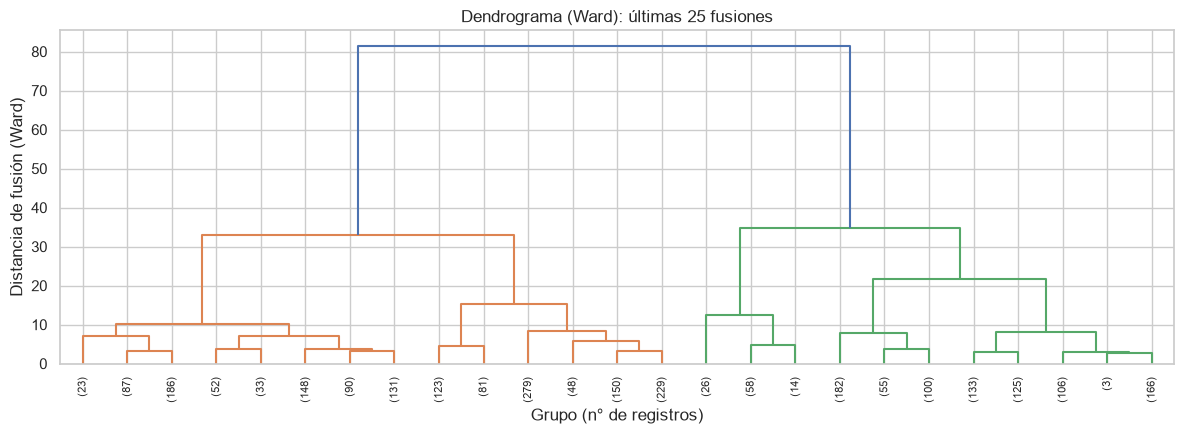

Silueta Ward: 0.5631
Coincidencia k-means vs. Ward (ARI): 0.9323


cluster_ward,1,2
cluster_kmeans,,
0,26,949
1,1634,19


In [4]:
# 12.3 Clustering jerárquico (Ward) y dendrograma truncado
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X_clu, method="ward")

plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=25, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma (Ward): últimas 25 fusiones")
plt.xlabel("Grupo (n° de registros)")
plt.ylabel("Distancia de fusión (Ward)")
plt.tight_layout()
plt.show()

segmentos["cluster_ward"] = fcluster(Z, t=k_elegido, criterion="maxclust")
print("Silueta Ward:", round(silhouette_score(X_clu, segmentos["cluster_ward"]), 4))
print("Coincidencia k-means vs. Ward (ARI):", round(adjusted_rand_score(segmentos["cluster_kmeans"], segmentos["cluster_ward"]), 4))
pd.crosstab(segmentos["cluster_kmeans"], segmentos["cluster_ward"])

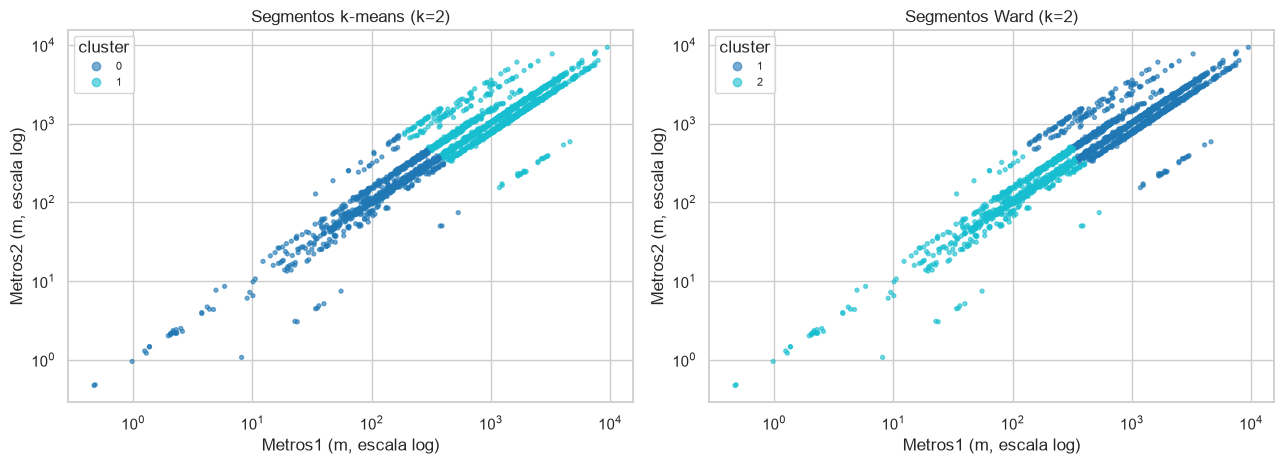

Coincidencia clusters vs. Format_Reporte (ARI): 0.2152


Format_Reporte,B,C,M,S
cluster_kmeans,,,,
0,0.320,0.067,0.545,0.069
1,0.166,0.377,0.049,0.408


In [5]:
# 12.4 Visualización 2D: las dos features son el propio plano (no hace falta PCA)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, titulo in [(axes[0], "cluster_kmeans", "k-means"), (axes[1], "cluster_ward", "Ward")]:
    puntos = ax.scatter(segmentos["Metros1"], segmentos["Metros2"], c=segmentos[col], cmap="tab10", s=8, alpha=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(title=f"Segmentos {titulo} (k={k_elegido})", xlabel="Metros1 (m, escala log)", ylabel="Metros2 (m, escala log)")
    ax.legend(*puntos.legend_elements(), title="cluster", fontsize=8)
plt.tight_layout()
plt.show()

# Solo para interpretar (el target NO se usó para armar los clusters)
print("Coincidencia clusters vs. Format_Reporte (ARI):", round(adjusted_rand_score(train[target], km.labels_), 4))
pd.crosstab(segmentos["cluster_kmeans"], train[target], normalize="index").round(3)

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Sin target:** el clustering se hace **sin `Format_Reporte`** y solo con train.
- **Features:** las numéricas de comportamiento, `Metros1` y `Metros2`.
  - Excluimos `Año` porque es un índice temporal: agruparía por año, no por comportamiento de ventas.
  - Excluimos `Sucursal_ID` y `Tela_ID` porque son códigos.
- **Transformación:** `log1p` antes de escalar, porque las distribuciones son muy asimétricas y sin log k-means quedaría dominado por los pocos registros de altísimo volumen. Después `StandardScaler`, para que las dos variables pesen igual en la distancia.
- **k-means:** evaluamos k = 2..10 con inercia (codo) y silueta, y elegimos k por la silueta máxima.
- **Ward:** clustering jerárquico con dendrograma truncado en las últimas 25 fusiones, cortado en el mismo k para comparar.
- **Visualización:** como hay solo 2 features, el propio plano Metros1 × Metros2 (en escala log) es la representación 2D y no hace falta PCA.

**Interpretación de los resultados:**
- **Elección de k:** la silueta es máxima en **k = 2** (0,568) y baja de forma sostenida después (0,50 con k = 3, 0,40 con k = 10). El codo no es marcado: la inercia cae suavemente.
- **Perfiles de los segmentos:**
  - **Cluster 0, "bajo volumen por período":** 975 registros, con medianas de ~145 m y ~162 m, y centroide en ~115/128 m.
  - **Cluster 1, "alto volumen por período":** 1.653 registros, con medianas de ~1.141 m y ~1.121 m, y centroide en ~1.104/1.153 m.
  - En los dos, la variación entre el segundo y el primer período es casi 1 (1,03 y 1,01).
- **Ward:** da casi la misma partición (silueta 0,563, ARI 0,93 contra k-means). El dendrograma muestra una gran distancia en la última fusión: dos grupos bien separados.
- **Relación con el target (solo para interpretar, sin usarlo para construir los grupos):**
  - El cluster 0 es 54,5% M y 32% B.
  - El cluster 1 es 40,8% S y 37,7% C.
  - El ARI contra el target es 0,215.

**Pregunta de análisis:** ¿Qué grupos de ventas aparecen? ¿Los clusters tienen utilidad comercial? ¿Por qué no equivalen a las clases del target?
- **Qué grupos aparecen:** un grupo de registros de bajo volumen por período (~150 m) y otro de alto volumen (~1.100 m).
- **Utilidad comercial:** limitada pero real. Separa combinaciones sucursal–tela de baja rotación (o reportadas con períodos cortos) de las de alta rotación, y sirve para priorizar stock o seguimiento. Pero buena parte de la separación se explica por **la duración del período del reporte** y no solo por la demanda. Para un uso comercial convendría normalizar los metros por mes antes de segmentar.
- **Por qué no equivalen a las clases:** el clustering agrupa por similitud en las features elegidas, mientras que el target es una etiqueta definida por otro criterio (el formato del reporte).
  - Volumen bajo no implica M ni B: B y M comparten el cluster 0.
  - C y S tienen volúmenes casi iguales y caen juntos en el cluster 1.
  - Por eso el ARI es solo 0,215.

**Limitaciones o mejoras posibles:**
- Con solo dos features muy correlacionadas, los grupos son esencialmente "chico" contra "grande".
- Sumar features derivadas, como metros por mes o la tendencia entre períodos, o perfiles agregados por sucursal o tela, daría segmentos más ricos.
- Las métricas internas (silueta) no garantizan utilidad de negocio.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
